# Exercise Sheet for Interpolation and Approximation
----------------------------------------------------------

In [6]:
#load some python packages you will need
import numpy as np                 #this helps compute things
import matplotlib.pyplot as plt    #this helps plot things

## Question 1
### a) Compute via interpolation and plot the Lagrange polynomial p(x) to $f(x) = cos(-2\pi x) + 0.4x^2$ over
### $(x_i,y_i) = [(7.2,21.04),(7.4,21.12),(7.6,22.39),(7.8,24.77]$ 


### b) Estimate the maximum absolute error bound for this Lagrange polynomial approximation over $\xi \in [x_0,x_n]$

In [18]:
x = np.arange(7,8,0.001)   #dummy range for function
y = np.cos(-2*np.pi*x) +0.4*x**2  #function f(x)


In [19]:
xi = np.array((7.2,7.4,7.6,7.8))   # points for interpolation
yi = y[np.digitize(xi,x)]


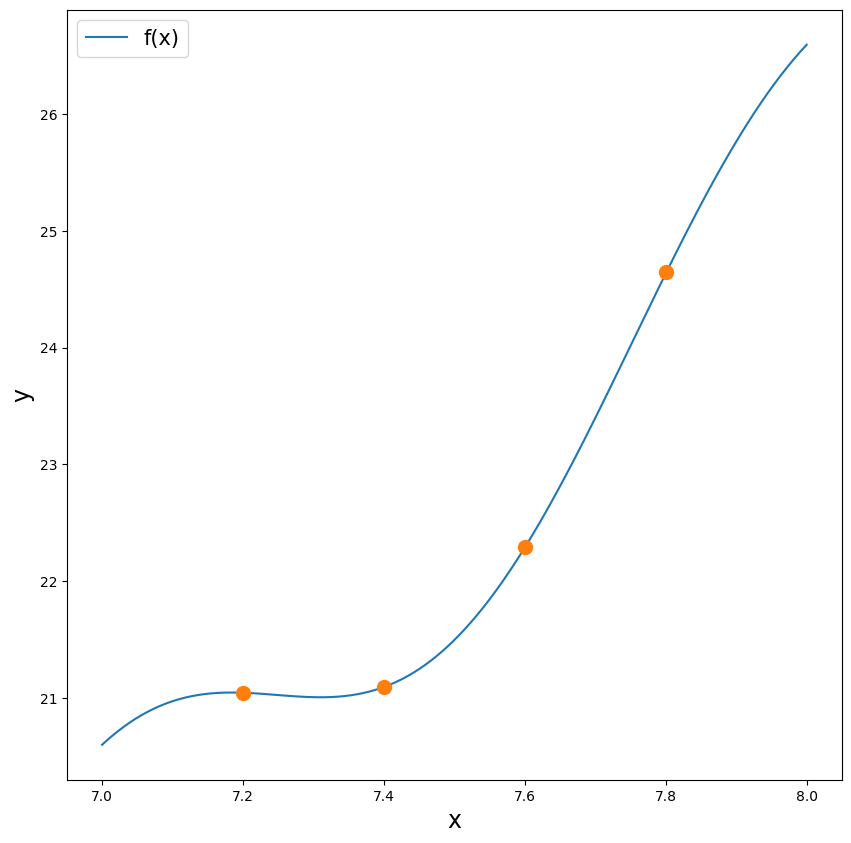

In [20]:
plt.figure(figsize=(10,10))
plt.plot(x,y,label='f(x)')  
plt.plot(xi,yi,'o',markersize=10)
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)
plt.legend(loc='best',fontsize=15)


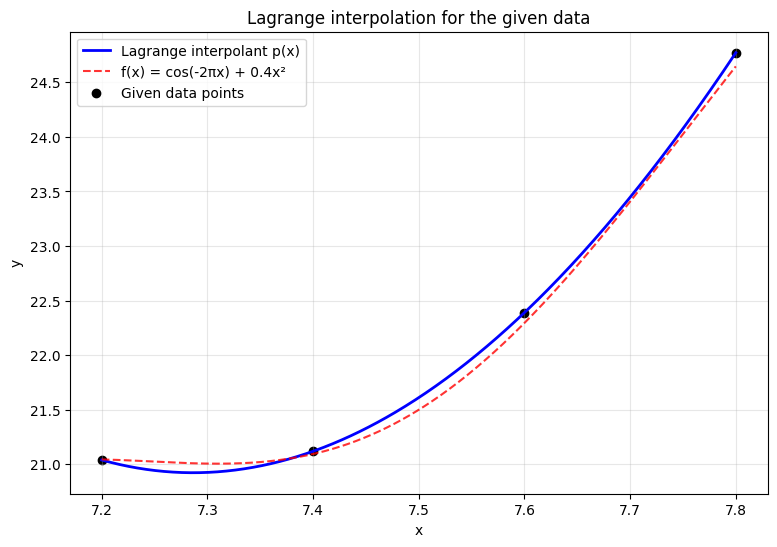

Interpolating polynomial in power form:
p(x) ≈ -1.6666666667x^3 + 51.8749999997x^2 + -490.5083333307x + 1485.5799999934

M4 = 1558.5454565440
max |Π(x - x_i)| over [7.2, 7.8] = 0.001600000000

Maximum absolute error bound:
|f(x) - p(x)| <= 0.103903030428


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial, pi


# ------------------------------------------------------------
# Exercise 1
# f(x) = cos(-2*pi*x) + 0.4*x^2
# Data points:
# (7.2, 21.04), (7.4, 21.12), (7.6, 22.39), (7.8, 24.77)
# ------------------------------------------------------------

x_nodes = np.array([7.2, 7.4, 7.6, 7.8])
y_vals = np.array([21.04, 21.12, 22.39, 24.77])

def f(x):
    # cos(-2*pi*x) = cos(2*pi*x), so both forms are equivalent.
    # We keep the form from the exercise for consistency.
    return np.cos(-2*np.pi*x) + 0.4*x**2


# ------------------------------------------------------------
# 1(a): Lagrange interpolation polynomial p(x)
# We build p(x) = sum_i y_i * L_i(x), where
# L_i(x) = product_{j != i} (x - x_j)/(x_i - x_j)
#
# This is the classical Lagrange form of the interpolating polynomial.
# ------------------------------------------------------------
def lagrange_poly(x_eval):
    x_eval = np.asarray(x_eval, dtype=float)
    result = np.zeros_like(x_eval, dtype=float)

    for i, xi in enumerate(x_nodes):
        basis = np.ones_like(x_eval, dtype=float)

        # Multiply the basis term L_i(x) = Π_{j != i} (x - x_j)/(x_i - x_j)
        for j, xj in enumerate(x_nodes):
            if i != j:
                basis *= (x_eval - xj) / (xi - xj)

        result += y_vals[i] * basis

    return result


# Create a dense grid for plotting
x_plot = np.linspace(7.2, 7.8, 500)

# Interpolating polynomial values
p_values = lagrange_poly(x_plot)

# Original function values (for comparison, not necessarily exact matching to the table)
f_values = f(x_plot)

# Plot the interpolating polynomial and the data points
plt.figure(figsize=(9, 6))
plt.plot(x_plot, p_values, label="Lagrange interpolant p(x)", color="blue", linewidth=2)
plt.plot(x_plot, f_values, label="f(x) = cos(-2πx) + 0.4x²", color="red", linestyle="--", alpha=0.8)
plt.scatter(x_nodes, y_vals, color="black", label="Given data points")
plt.title("Lagrange interpolation for the given data")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# ------------------------------------------------------------
# Optional: display the interpolating polynomial in power form
# The polynomial is computed numerically from the Lagrange basis.
# ------------------------------------------------------------
coeffs = np.polyfit(x_nodes, y_vals, 3)
print("Interpolating polynomial in power form:")
print(f"p(x) ≈ {coeffs[0]:.10f}x^3 + {coeffs[1]:.10f}x^2 + {coeffs[2]:.10f}x + {coeffs[3]:.10f}")

# This is the same polynomial, just written in descending powers:
# p(x) ≈ -1.6666667 x^3 + 51.875 x^2 - 490.508333 x + 1485.58
#
# The exact numeric coefficients may vary slightly depending on rounding,
# but the structure is the same.


# ------------------------------------------------------------
# 1(b): Error bound for Lagrange interpolation
#
# For an interpolating polynomial of degree n = 3:
#   f(x) - p(x) = f^(4)(ξ) / 4! * Π_{i=0}^3 (x - x_i)
#
# Taking absolute values:
#   |f(x) - p(x)| <= (max|f^(4)(t)| / 4!) * max_{x in [x0,xn]} |Π (x - x_i)|
#
# Here:
#   f(x) = cos(-2πx) + 0.4x^2
#   f^(4)(x) = 16π^4 cos(2πx)
#   because:
#       - derivatives of 0.4x^2 vanish after the second derivative
#       - the cosine part contributes 16π^4 cos(2πx)
#
# Thus:
#   max_{x in [7.2, 7.8]} |f^(4)(x)| = 16π^4
# ------------------------------------------------------------
M4 = 16 * pi**4  # maximum absolute value of the 4th derivative
print(f"\nM4 = {M4:.10f}")

# Compute max of |(x - x0)(x - x1)(x - x2)(x - x3)| over the interval
interval_grid = np.linspace(7.2, 7.8, 200000)
product_values = np.abs(
    (interval_grid - x_nodes[0]) *
    (interval_grid - x_nodes[1]) *
    (interval_grid - x_nodes[2]) *
    (interval_grid - x_nodes[3])
)

product_max = np.max(product_values)
print(f"max |Π(x - x_i)| over [7.2, 7.8] = {product_max:.12f}")

# Lagrange remainder bound
error_bound = (M4 / factorial(4)) * product_max
print(f"\nMaximum absolute error bound:")
print(f"|f(x) - p(x)| <= {error_bound:.12f}")


# Final result:
#   |f(x) - p(x)| <= 0.1039 for x in [7.2, 7.8]

----------------------------------------------------------

## Question 2
### Assume linear interpolation with step size $\textbf{d}$ is used to approximate $y(x) = \pi x^7$
### What step size for linear interpolation do you need to have for an absolute error $E_{max} < 10^{-6}$?. You can assume  $x \in [0,2]$.

----------------------------------------------------------

using $|E(x)| =< M/8 * (x_{i+1}-x_i)^2 =< 10^{-6}$ and M being the max of f''(x) rewriting said expression for d which is (x_(i+1)-x_i) got me the step size of $4,35*10^{-5}$

## Question 3
### When using Taylor polynomials to approximate $y = cos(-3 \pi x) + 3x$ over the range $x = [-0.25,0.25]$, about $x= 0$;  to what order $j$ would you need to compute the interpolating polynomial in order to keep the maximum absolute error smaller than $E_{j}(x) < 10^{-6}$?

The smallest Taylor polynomial that satisfies the error bound is of degree 14, so j = 14.

Why:

$f(x) = cos(-3πx) + 3x = cos(3πx) + 3x$

Its Maclaurin series is

$cos(3πx) = 1 - (3πx)^2 / 2! + (3πx)^4 / 4! - (3πx)^6 / 6! + ...$

so

$f(x) = 1 + 3x - (3π)^2 x^2 / 2! + (3π)^4 x^4 / 4! - ...$

Notice the cos part has only even powers, so the $x^{13}$ term is actually zero. That means the polynomial of degree 13 is the same as the polynomial of degree 12. For a Taylor remainder on 
$|x| ≤ 0.25$, the first neglected term after degree 13 is the $x^{14}$ term:

$|R_{13}(x)| ≈ (3π · 0.25)^{14} / 14! ≈ 1.86 × 10^{-6}$

This is still larger than $10^{-6}$. For degree 14, the first neglected term is $x^{16}$:

$|R_{14}(x)| ≈ (3π · 0.25)^{16} / 16! ≈ 4.31 × 10^{-8}$

and this is below $10^{-6}$. Therefore the minimum order is: j = 14

Text(0, 0.5, 'y')

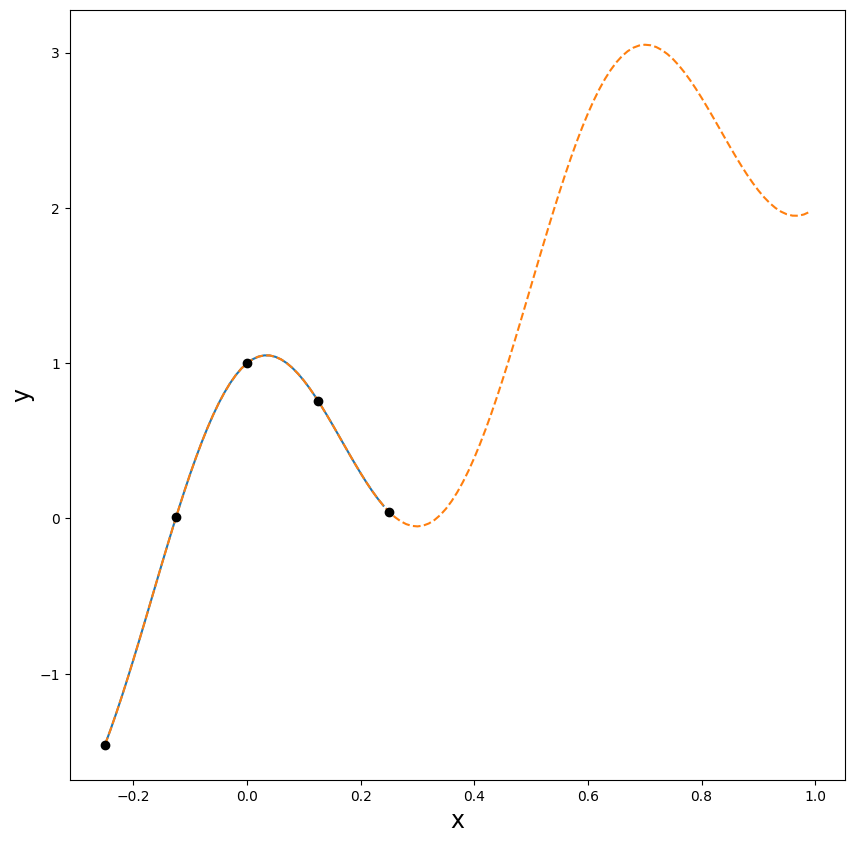

In [32]:
xi = np.arange(-0.25,1,0.01)
xdum = np.arange(-0.25,0.25,0.01)
x = np.array([-0.25,-0.125,0,0.125,0.25])
y = np.cos(-3*np.pi*x) + 3*x
ydum = np.cos(-3*np.pi*xdum) + 3*xdum
yi = np.cos(-3*np.pi*xi) + 3*xi

plt.figure(figsize=(10,10))
plt.plot(xdum,ydum)
plt.plot(xi,yi,'--')
plt.plot(x,y,'o',c='black')
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)

----------------------------------------------------------

## Question 4
## Use bilinear interpolation to determine the value of the function $f(x,y) = z$  at the point $(x_r, y_r)$, given the below four data points $x_i, y_i$ with values $z_{i} = f(x_i,y_i)$


For the four corner values

$z_{11} = f(0,0) = -0.7$, $z_{12} = f(0,1) = 0.3$, $z_{22} = f(1,1) = 2.4$, $z_{21} = f(1,0) = 2.6$

the bilinear interpolation formula on the unit square is

$f(x_r, y_r) = (1 - x_r)(1 - y_r)\, z_{11} + x_r(1 - y_r)\, z_{21} + (1 - x_r)\, y_r\, z_{12} + x_r\, y_r\, z_{22}$

Substituting the values:

$f(x_r, y_r) = -0.7\,(1 - x_r)(1 - y_r) + 2.6\, x_r(1 - y_r) + 0.3\,(1 - x_r)\, y_r + 2.4\, x_r y_r$

This simplifies to

$z = -0.7 + 3.3\,x_r + y_r - 1.2\,x_r y_r$

Text(0.5210825366678629, 0.055270699432600295, '($x_r,y_r)$')

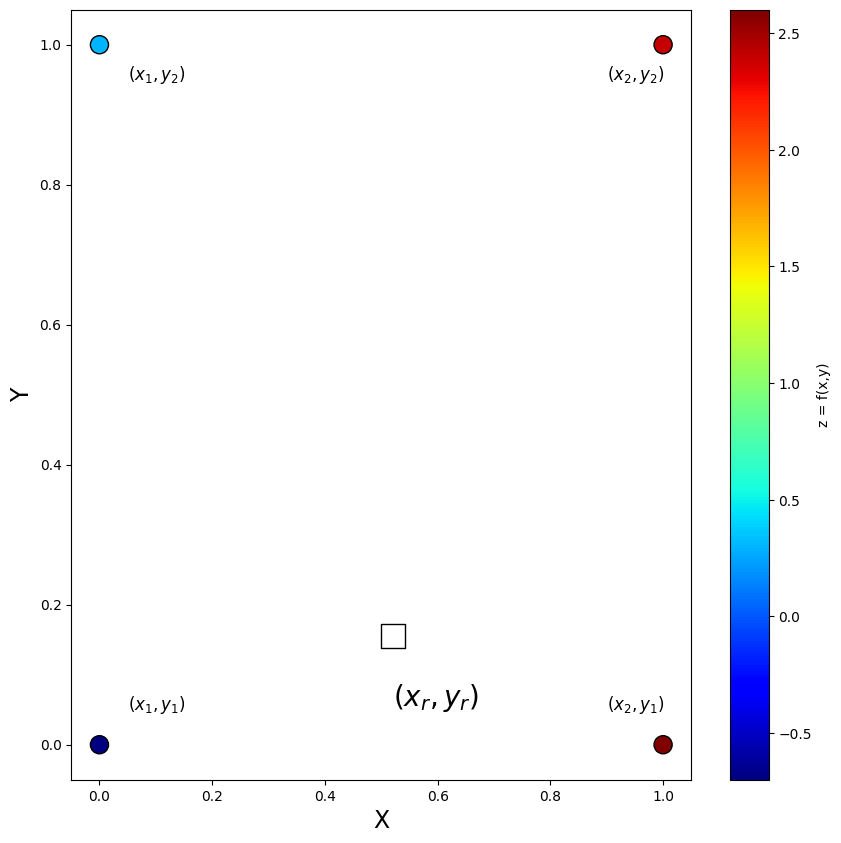

In [25]:
#Known data points and function values.  Listed clockwise from the x_1,y_1 = (0,0) point.
xi = np.array([0,0,1,1])  #x_1,x_1,x_2,x_2
yi = np.array([0,1,1,0])  #y_1,y_2,y_2,y_1
zi = np.array([-0.7,0.3,2.4,2.6])  

#Randomly generate coordinates to find function value (z = f(x,y)) at 
xr = np.random.uniform()
yr = np.random.uniform()

#Visualize
plt.figure(figsize=(10,10))
plt.scatter(xi,yi,c=zi,s=170,marker='o',cmap='jet',edgecolor='black')
plt.colorbar(label='z = f(x,y)')
plt.xlabel('X',fontsize=17)
plt.ylabel('Y',fontsize=17)
plt.scatter(xr,yr,edgecolor='black',marker='s',s=290,c='white')
plt.text(0.05,0.05,'($x_1,y_1)$',fontsize=12)
plt.text(0.05,0.95,'($x_1,y_2)$',fontsize=12)
plt.text(0.9,0.95,'($x_2,y_2)$',fontsize=12)
plt.text(0.9,0.05,'($x_2,y_1)$',fontsize=12)
plt.text(xr,yr-0.1,'($x_r,y_r)$',fontsize=20)



